# 03. Graduate Depth Analysis: SHAP Attributions, Feature Ablation & Error Audit

**Project:** Sequence-Derived Protein Solubility Prediction in the *E. coli* eSOL Dataset  
**Mode:** Read-Only Depth Analysis Showcase (displays saved SHAP plots, ablation tables, GRAVY stratification, and high-error case inspections without saving any files)

### Overview
1. **Global SHAP Feature Attribution:** Inspect the top sequence determinants driving predictions (`seq_length`, `net_charge_density`, `mw_kda_reported`, `pi_reported`, and lagged autocorrelations).
2. **Feature-Family Ablation Study:** Examine performance on unsmoothed, measured targets across isolated and leave-one-family-out feature subsets.
3. **Hydropathy (GRAVY) Stratification:** Analyze predicted vs. actual solubility trends across hydrophilic and hydrophobic sequence regimes.
4. **High-Error Case Audit:** Inspect the top holdout proteins with the largest prediction residuals.

--- Global SHAP Beeswarm Attribution Plot ---


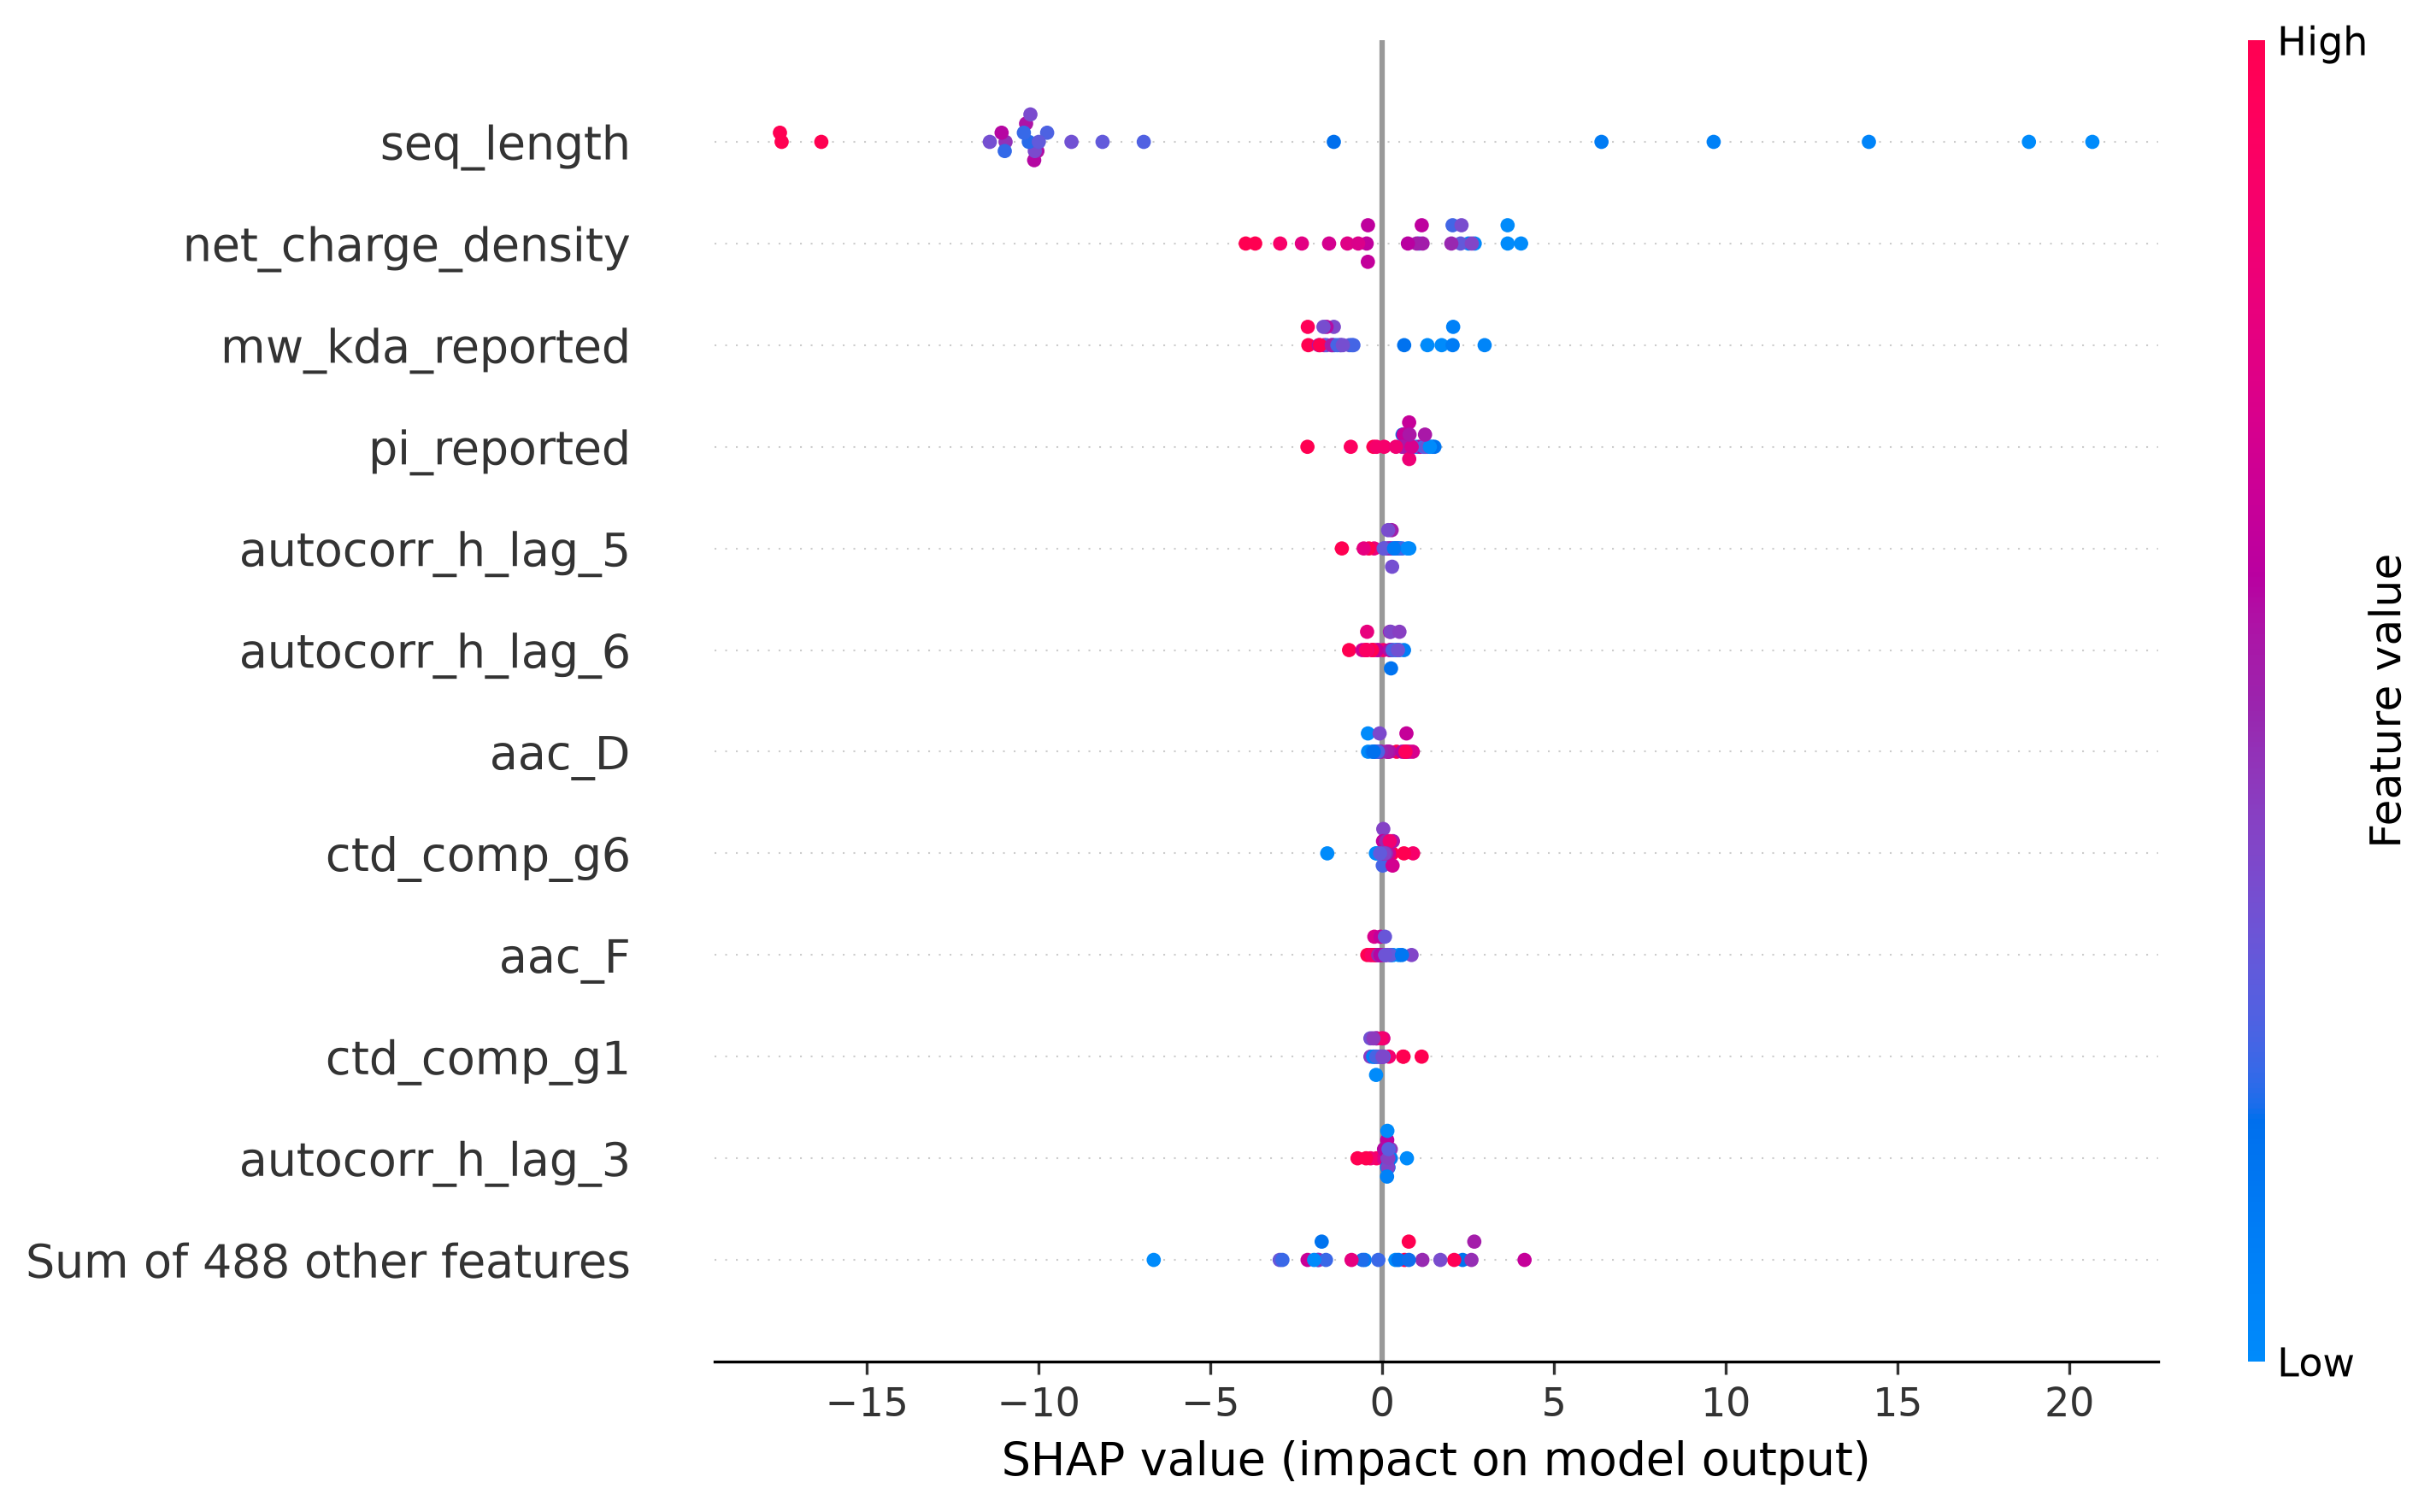

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

def resolve_path(*candidates):
    for p in candidates:
        if os.path.exists(p):
            return p
    return None

shap_path = resolve_path("../results/figures/shap_summary_plot.png", "results/figures/shap_summary_plot.png")
if shap_path:
    print("--- Global SHAP Beeswarm Attribution Plot ---")
    display(Image(filename=shap_path, width=720))

### 1. Feature-Family Ablation Study (Unsmoothed Measured Targets)
Evaluating individual feature groups and leave-one-family-out drops isolates each descriptor family's standalone and marginal predictive signal.

Saved Feature-Family Ablation Table:


,Experiment,Feature_Group,Feature_Count,R2,RMSE,RMSE_CI_95_Lower,RMSE_CI_95_Upper,MAE,RMSE_Delta_vs_All
0,E0,Mean-only baseline,0,-0.007219,34.608933,33.081106,36.266300,30.647663,8.606188
1,E1,Reported molecular properties,2,0.271035,29.442835,27.640067,31.216037,24.176575,3.440090
2,E2,Sequence summary properties,5,0.211470,30.622131,28.567944,32.614568,24.829890,4.619385
3,E3,Amino-acid composition,20,0.384672,27.050774,25.120036,28.991737,21.336935,1.048029
4,E4,All available features,499,0.431427,26.002745,24.172680,27.824506,20.693377,0.000000
5,E5,All except reported properties,497,0.413342,26.413055,24.502593,28.272869,20.897048,0.410309
6,E6,All except sequence summaries,494,0.418248,26.302375,24.305716,28.123797,20.853679,0.299629
7,E7,All except amino-acid composition,479,0.398249,26.750677,24.737072,28.716324,21.225762,0.747932



--- Feature-Family Ablation RMSE Plot ---


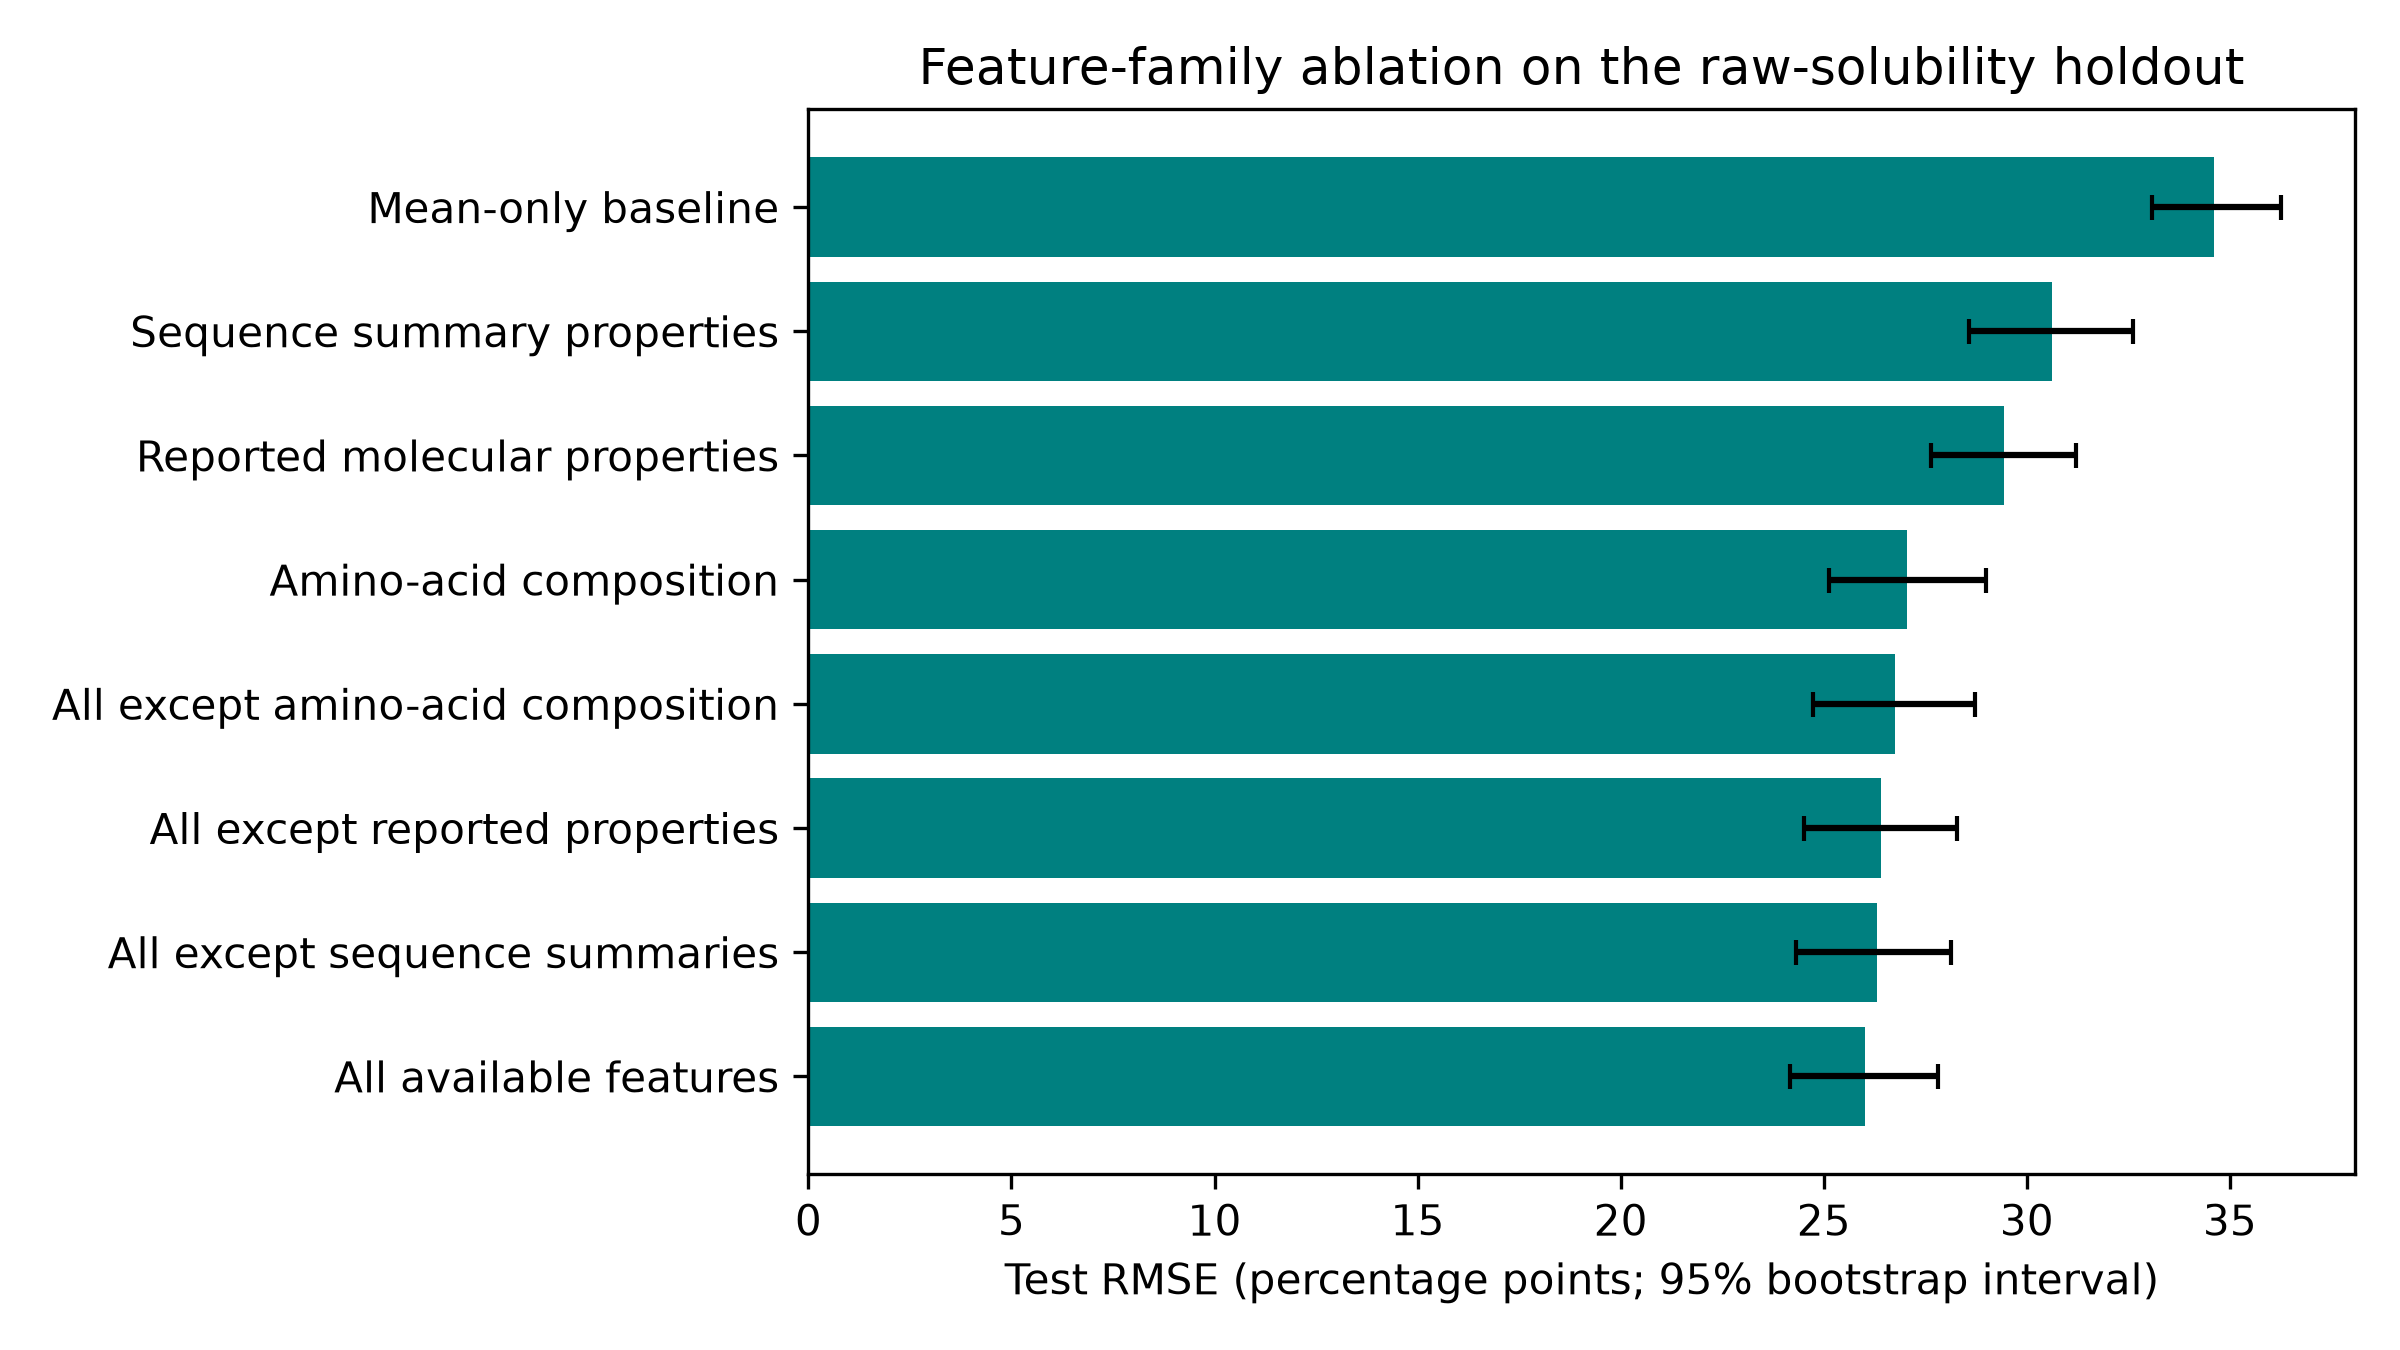

In [2]:
ablation_csv = resolve_path("../results/tables/feature_ablation.csv", "results/tables/feature_ablation.csv")
ablation_fig = resolve_path("../results/figures/feature_ablation_rmse.png", "results/figures/feature_ablation_rmse.png")

if ablation_csv:
    print("Saved Feature-Family Ablation Table:")
    display(pd.read_csv(ablation_csv))

if ablation_fig:
    print("\n--- Feature-Family Ablation RMSE Plot ---")
    display(Image(filename=ablation_fig, width=680))

### 2. Hydropathy (GRAVY) Stratification
Hydrophilic proteins (negative GRAVY scores) consistently achieve higher solubility than hydrophobic sequences.

--- GRAVY Hydropathy vs. Solubility Stratification ---


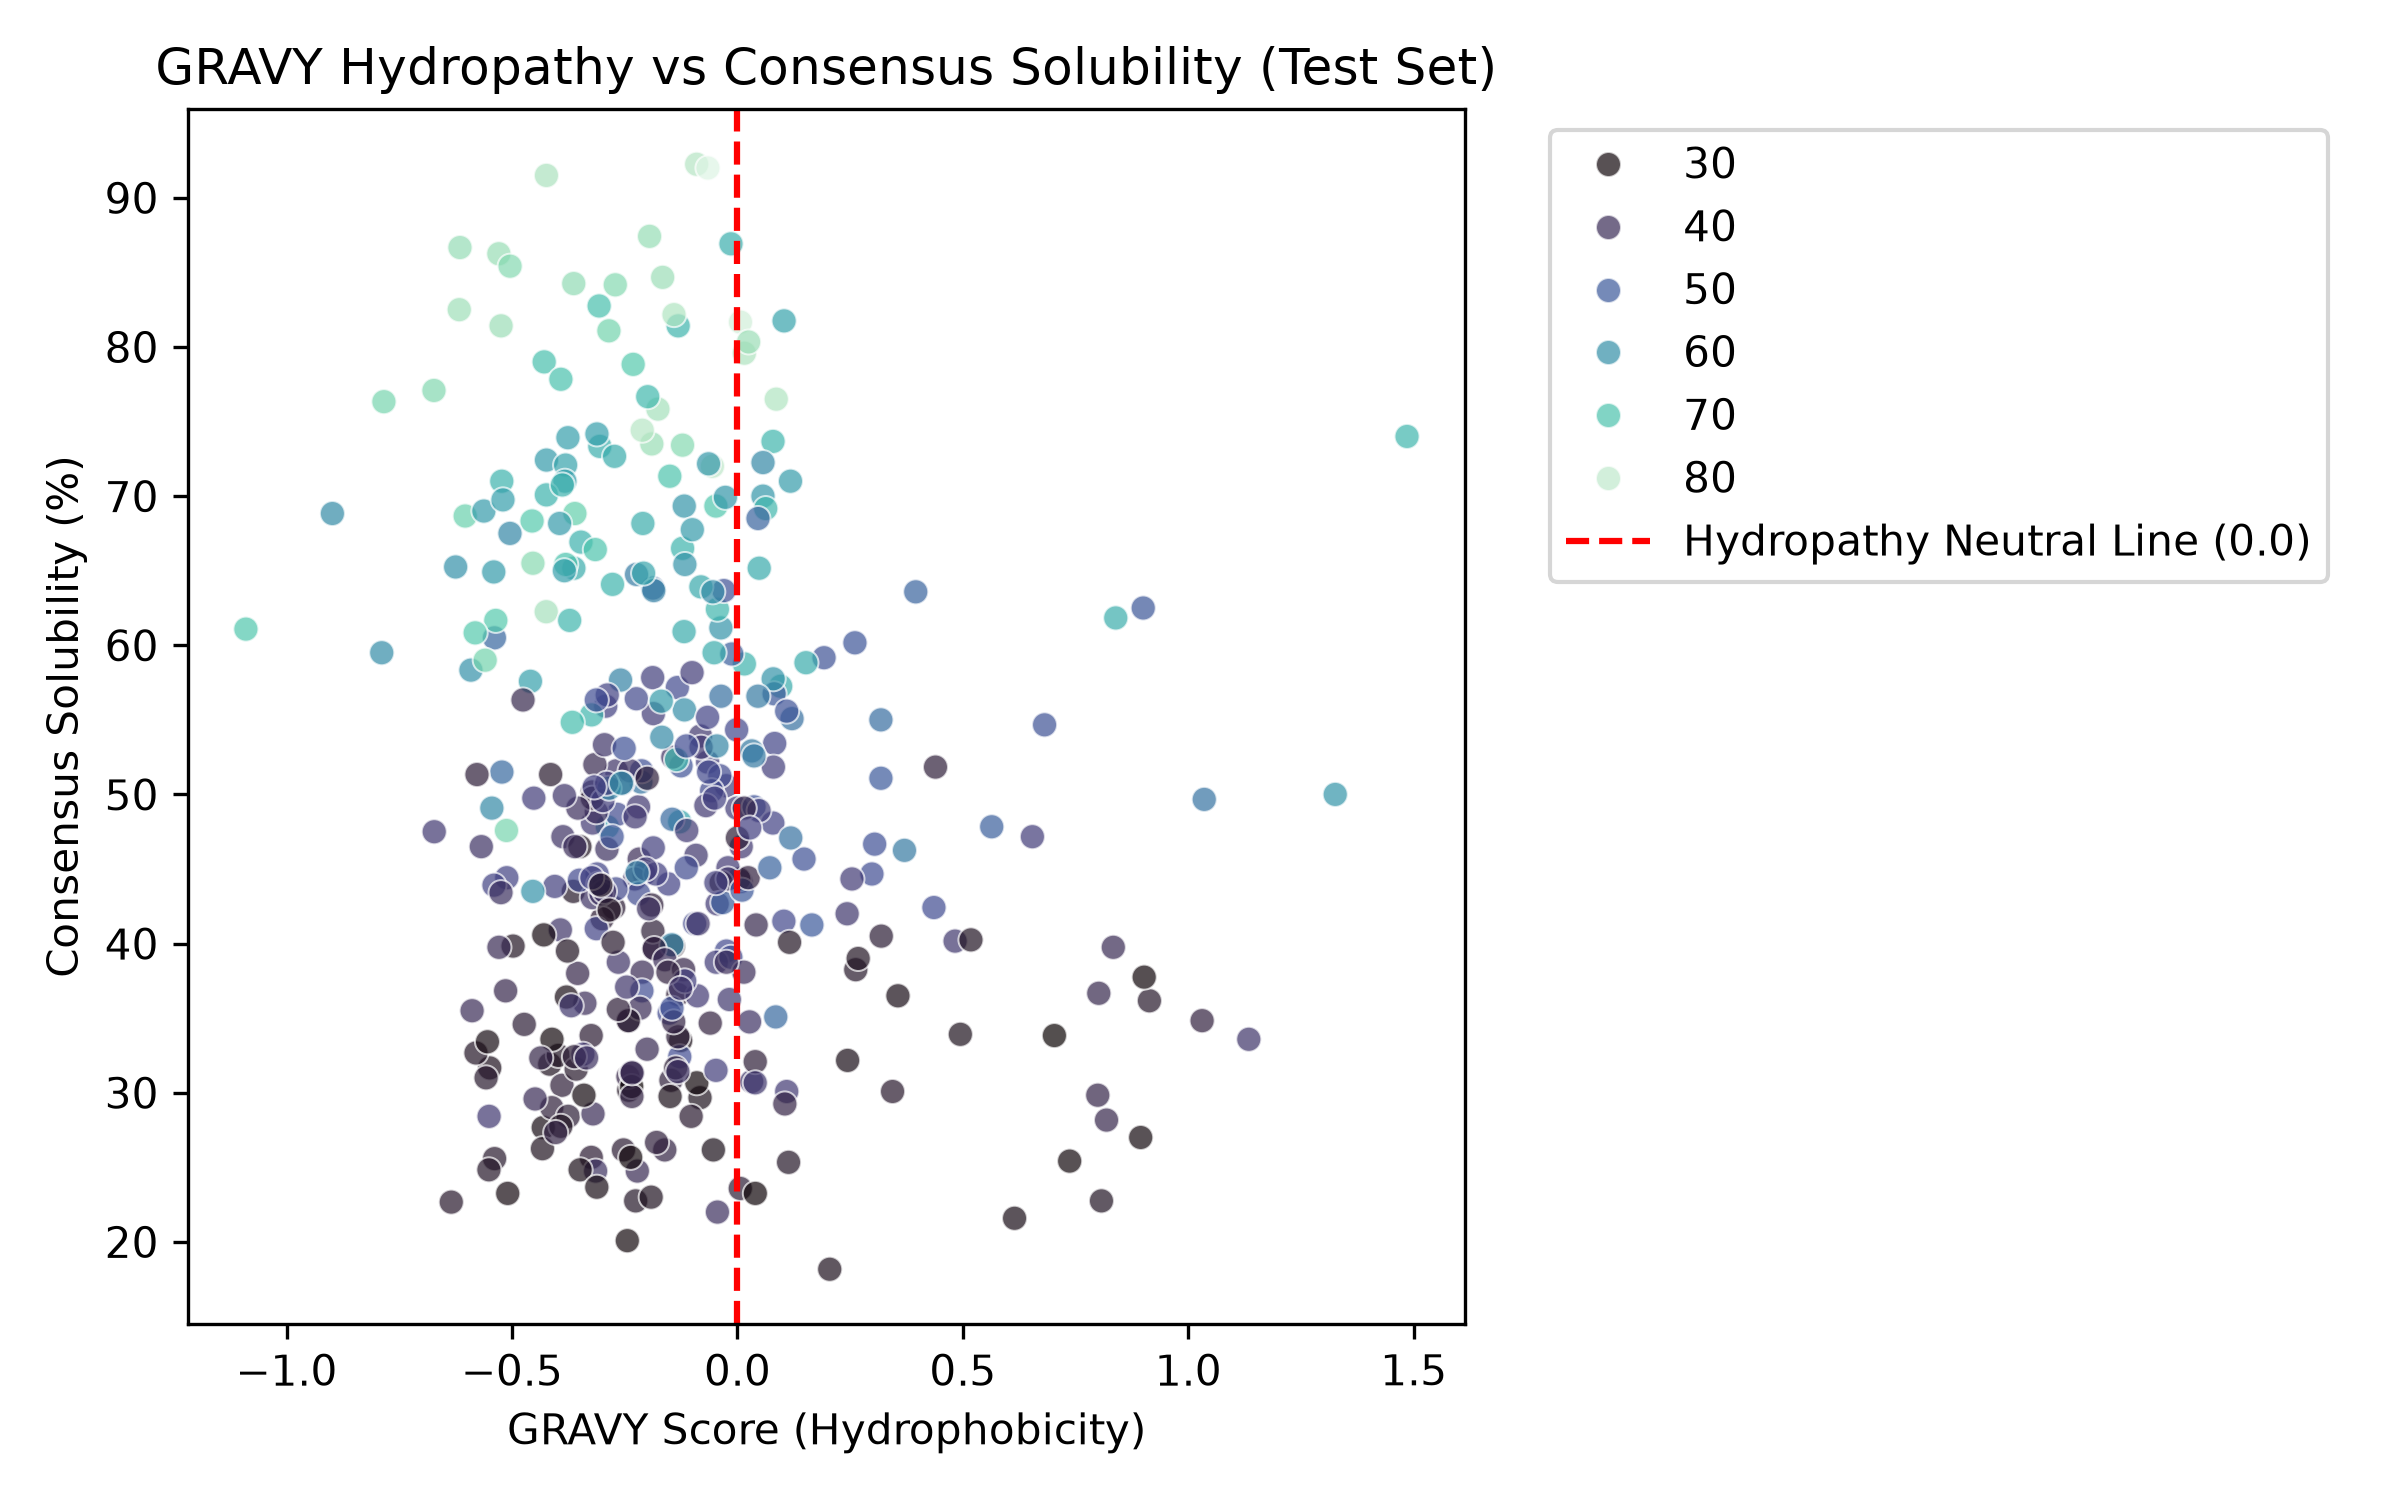

In [3]:
gravy_fig = resolve_path("../results/figures/gravy_vs_solubility.png", "results/figures/gravy_vs_solubility.png")
if gravy_fig:
    print("--- GRAVY Hydropathy vs. Solubility Stratification ---")
    display(Image(filename=gravy_fig, width=680))

### 3. Top High-Error Case Inspection
Auditing the largest holdout prediction residuals identifies failure modes in large multi-domain proteins and specialized membrane-associated sequences.

Top 10 Highest-Error Holdout Proteins:


,gene,locus,Solubility (%),Consensus_Solubility,Predicted_Solubility,Absolute_Error
0,yafY,yafY,27.0,47.583333,73.973777,26.390444
1,ypdI,ypdI,23.0,86.916667,65.854363,21.062304
2,alsK,alsK,31.0,22.000000,40.781896,18.781896
3,yahD,yahD,33.0,81.750000,63.886257,17.863743
4,fliF,fliF,55.0,56.333333,38.749192,17.584141
5,ppdA,ppdA,11.0,39.916667,57.478134,17.561467
6,ruvC,ruvC,18.0,35.083333,52.436511,17.353178
7,pal,pal,81.0,43.500000,60.582351,17.082351
8,htrE,htrE,9.0,51.333333,34.542314,16.791020
9,ucpA,ucpA,79.0,68.500000,51.735537,16.764463


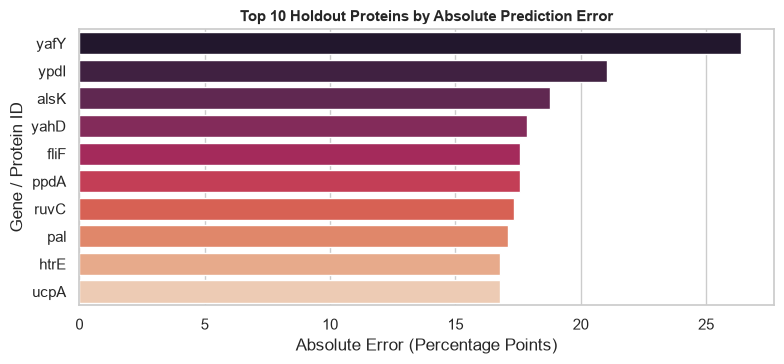

In [4]:
err_csv = resolve_path("../results/tables/top_10_high_error_cases.csv", "results/tables/top_10_high_error_cases.csv")
if err_csv:
    err_df = pd.read_csv(err_csv)
    print("Top 10 Highest-Error Holdout Proteins:")
    display(err_df)

    # Inline error magnitude bar chart (display only, not saved)
    label_col = "gene" if "gene" in err_df.columns else err_df.columns[0]
    err_col = "Absolute_Error" if "Absolute_Error" in err_df.columns else err_df.columns[-1]

    fig, ax = plt.subplots(figsize=(8, 3.8))
    sns.barplot(data=err_df, x=err_col, y=label_col, palette="rocket", ax=ax)
    ax.set_title("Top 10 Holdout Proteins by Absolute Prediction Error", fontsize=11, fontweight="bold")
    ax.set_xlabel("Absolute Error (Percentage Points)")
    ax.set_ylabel("Gene / Protein ID")
    plt.tight_layout()
    plt.show()